# Create Euclidean Distance

We're going to create Euclidean Distance Raster Maps for: 

1. Highways 
2. Parks 

So we can grab more landscape-level variables. 



# Data Sources 
## Highway 
US Bureau of Transportation Statistics
California State Highway 
Updated 2023
https://gis.data.ca.gov/datasets/77f2d7ba94e040a78bfbe36feb6279da_0/explore?location=37.730945%2C-122.427948%2C13&showTable=true





In [ ]:
from osgeo import gdal, ogr, osr
import os
gdal.UseExceptions()

# Input/Output paths (Use the same highway tif shapeflie from LA since it's statewide)
shape_file = "/home/oliver/gdrive/Chapter1_LA_redlining/data/dependent_var/State_Highway_Network_Lines.geojson"
county_file = "/home/oliver/gdrive/Chapter1_SF_redlining_Rprj/data/dependent_var/redlining/SF_HOLC_cleaned.geojson"  # Adjust path
out_raster = "/home/oliver/gdrive/Chapter1_SF_redlining_Rprj/data/dependent_var/euc_highway_sf_3m.tif"
temp_raster = "/home/oliver/temp_highway.tif"
temp_highway_utm = "/home/oliver/temp_highway_utm.geojson"
temp_county_utm = "/home/oliver/temp_county_utm.geojson"

# Parameters
pixel_size = 3  # 50 meters
nodata = -9999

target_epsg = 26910  # NAD83 UTM 10N - best for SF

print("="*60)
print("STEP 1: Reprojecting Highway shapefile to UTM 10N")
print("="*60)


STEP 1: Reprojecting Highway shapefile to UTM 10N


In [10]:

# Reproject highways to UTM 10N
gdal.VectorTranslate(
    temp_highway_utm,
    shape_file,
    format='GeoJSON',
    dstSRS=f'EPSG:{target_epsg}',
    reproject=True
)
print(f"✓ Highways reprojected to EPSG:{target_epsg}")

print("\n" + "="*60)
print("STEP 2: Reprojecting LA County boundary to UTM 10N")
print("="*60)

# Reproject sf_holc boundary to UTM 10N
gdal.VectorTranslate(
    temp_county_utm,
    county_file,
    format='GeoJSON',
    dstSRS=f'EPSG:{target_epsg}',
    reproject=True
)
print(f"✓ SF County boundary reprojected to EPSG:{target_epsg}")

print("\n" + "="*60)
print("STEP 3: Extract extent from SF County boundary")
print("="*60)

# Open reprojected SF County to get extent
county_ds = ogr.Open(temp_county_utm)
county_lyr = county_ds.GetLayer()
xmin, xmax, ymin, ymax = county_lyr.GetExtent()
county_srs = county_lyr.GetSpatialRef()

print(f"SF County Extent (UTM 10N, meters):")
print(f"  xmin={xmin:.2f}, xmax={xmax:.2f}")
print(f"  ymin={ymin:.2f}, ymax={ymax:.2f}")
print(f"  Width: {(xmax-xmin)/1000:.2f} km")
print(f"  Height: {(ymax-ymin)/1000:.2f} km")

# Optional: Get county geometry for spatial filter
county_feat = county_lyr.GetNextFeature()
county_geom = county_feat.GetGeometryRef().Clone()
county_ds = None

print("\n" + "="*60)
print("STEP 4: Apply spatial filter to highways")
print("="*60)

# Open reprojected highways and apply spatial filter
highway_ds = ogr.Open(temp_highway_utm)
highway_lyr = highway_ds.GetLayer()

# Set spatial filter to only include highways within LA County
highway_lyr.SetSpatialFilter(county_geom)

print(f"Original highway features: {highway_lyr.GetFeatureCount()}")
highway_lyr.SetSpatialFilter(county_geom)
print(f"Highways within LA County: {highway_lyr.GetFeatureCount()}")

highway_ds = None

print("\n" + "="*60)
print("STEP 5: Rasterizing highways")
print("="*60)

# Calculate raster dimensions
x_res = int((xmax - xmin) / pixel_size)
y_res = int((ymax - ymin) / pixel_size)

print(f"Raster dimensions: {x_res} x {y_res} pixels")
print(f"This will create a {x_res * y_res / 1e6:.2f} million pixel raster")
print(f"Pixel size: {pixel_size} meters")

# Open the reprojected highway file for rasterization
shp_ds = gdal.OpenEx(temp_highway_utm, gdal.OF_VECTOR)

# Rasterize all highways within LA County extent
rasterize_ds = gdal.Rasterize(
    temp_raster, 
    shp_ds,
    outputType=gdal.GDT_Byte,
    format='GTiff',
    creationOptions=["COMPRESS=DEFLATE", "TILED=YES", "BIGTIFF=YES"],
    noData=nodata,
    initValues=nodata,
    xRes=pixel_size,
    yRes=pixel_size,
    outputBounds=(xmin, ymin, xmax, ymax),
    outputSRS=f'EPSG:{target_epsg}',
    allTouched=True,
    burnValues=[1],
    # Optional: add cutline to clip exactly to county boundary
    # cutlineDSName=temp_county_utm,
    # cropToCutline=True
)
rasterize_ds = None
shp_ds = None

print("✓ Rasterization complete")

print("\n" + "="*60)
print("STEP 6: Computing Euclidean distance")
print("="*60)

# Compute proximity (Euclidean distance)
src_ds = gdal.Open(temp_raster, gdal.GA_ReadOnly)
src_band = src_ds.GetRasterBand(1)

# Create output raster with same dimensions
driver = gdal.GetDriverByName('GTiff')
dst_ds = driver.Create(
    out_raster,
    src_ds.RasterXSize,
    src_ds.RasterYSize,
    1,
    gdal.GDT_Float32,
    options=["COMPRESS=DEFLATE", "TILED=YES", "BIGTIFF=IF_SAFER"]
)
dst_ds.SetGeoTransform(src_ds.GetGeoTransform())
dst_ds.SetProjection(src_ds.GetProjection())
dst_band = dst_ds.GetRasterBand(1)
dst_band.SetNoDataValue(nodata)

# Compute proximity - distance in meters (UTM units)
gdal.ComputeProximity(
    src_band, 
    dst_band, 
    options=['VALUES=1', 'DISTUNITS=GEO']  # GEO uses georeferenced coordinates (meters in UTM)
)

print("✓ Distance calculation complete")

# Cleanup
dst_band.FlushCache()
dst_band = None
src_band = None
dst_ds = None
src_ds = None

print("\n" + "="*60)
print("STEP 7: Cleaning up temporary files")
print("="*60)

# Remove temporary files
for temp_file in [temp_raster, temp_highway_utm, temp_county_utm]:
    if os.path.exists(temp_file):
        os.remove(temp_file)
        print(f"✓ Removed {os.path.basename(temp_file)}")

print("\n" + "="*60)
print("COMPLETE!")
print("="*60)
print(f"Output saved to: {out_raster}")
print(f"Projection: EPSG:{target_epsg} (NAD83 UTM 11N)")
print(f"Distance values are in METERS")
print(f"NoData value: {nodata}")
print("="*60)

Warning 1: Several coordinate operations have been used to transform layer HWY_SHN_Lines. Artifacts may appear. You may consider using the -ct_opt ALLOW_BALLPARK=NO and/or -ct_opt ONLY_BEST=YES warping options, or specify a particular coordinate operation with -ct. This warning can be silenced with -ct_opt WARN_ABOUT_DIFFERENT_COORD_OP=NO.


✓ Highways reprojected to EPSG:26910

STEP 2: Reprojecting LA County boundary to UTM 10N
✓ SF County boundary reprojected to EPSG:26910

STEP 3: Extract extent from SF County boundary
SF County Extent (UTM 10N, meters):
  xmin=543146.10, xmax=556161.76
  ymin=4173551.56, ymax=4184524.61
  Width: 13.02 km
  Height: 10.97 km

STEP 4: Apply spatial filter to highways
Original highway features: 2
Highways within LA County: 2

STEP 5: Rasterizing highways
Raster dimensions: 4338 x 3657 pixels
This will create a 15.86 million pixel raster
Pixel size: 3 meters
✓ Rasterization complete

STEP 6: Computing Euclidean distance
✓ Distance calculation complete

STEP 7: Cleaning up temporary files
✓ Removed temp_highway.tif
✓ Removed temp_highway_utm.geojson
✓ Removed temp_county_utm.geojson

COMPLETE!
Output saved to: /home/oliver/gdrive/Chapter1_SF_redlining_Rprj/data/dependent_var/euc_highway_sf_3m.tif
Projection: EPSG:26910 (NAD83 UTM 11N)
Distance values are in METERS
NoData value: -9999



## Parks
### San Francisco 
[San Francisco Parks and Rec](https://data.sf.gov/Culture-and-Recreation/Recreation-and-Parks-Properties/gtr9-ntp6/data_preview)

Make sure to investigate it in QGIS and explore the attributes. We got some property types that we don't really need so we're going to filter for just the ones that birds may like. 

We only want:  
'Regional Park', 
'Neighborhood Park or Playground', 
'Parkway', 
'Mini Park', 
'Community Garden', 
'Zoological Garden', 


In [1]:
from osgeo import gdal, ogr, osr
import os
gdal.UseExceptions()


# Input/Output paths
shape_file = "/home/oliver/gdrive/Chapter1_SF_redlining_Rprj/data/dependent_var/Recreation_and_Parks_Properties_20261119.geojson"

# Same boundary as the highway raster, so both rasters share the same extent and pixel grid
county_file = "/home/oliver/gdrive/Chapter1_SF_redlining_Rprj/data/dependent_var/redlining/SF_HOLC_cleaned.geojson"
out_raster = "/home/oliver/gdrive/Chapter1_SF_redlining_Rprj/data/dependent_var/euc_park_sf_3m.tif"
temp_raster = "/home/oliver/temp_park.tif"
temp_park_utm = "/home/oliver/temp_park_utm.geojson"
temp_county_utm = "/home/oliver/temp_county_utm.geojson"

# Parameters
pixel_size = 3   # meters 
nodata = -9999   # for the Float32 distance raster only (Byte can't hold -9999)

target_epsg = 26910  # NAD83 UTM 10N - same as the highway raster

print("="*60)
print("STEP 1: Reprojecting parks and SF HOLC boundary to UTM 10N")
print("="*60)

for src, dst in [(shape_file, temp_park_utm), (county_file, temp_county_utm)]:
    gdal.VectorTranslate(dst, src, format='GeoJSON',
                         dstSRS=f'EPSG:{target_epsg}', reproject=True,
                         makeValid=True)   # some park polygons are invalid
print(f"✓ Parks and boundary reprojected to EPSG:{target_epsg}")


STEP 1: Reprojecting parks and SF HOLC boundary to UTM 10N


Warning 1: Several coordinate operations have been used to transform layer Recreation_and_Parks_Properties_20261119. Artifacts may appear. You may consider using the -ct_opt ALLOW_BALLPARK=NO and/or -ct_opt ONLY_BEST=YES warping options, or specify a particular coordinate operation with -ct. This warning can be silenced with -ct_opt WARN_ABOUT_DIFFERENT_COORD_OP=NO.


✓ Parks and boundary reprojected to EPSG:26910


In [2]:
#Clean Shapefile

#We're going to filter out property type and then just join all the parks together as just one unit. 

from osgeo import gdal, ogr
gdal.UseExceptions()

ds = ogr.Open(shape_file)
layer_name = ds.GetLayer().GetName()

col = "propertytype"
res = ds.ExecuteSQL(f'SELECT DISTINCT {col} FROM "{layer_name}"')
print([f.GetField(0) for f in res])
ds.ReleaseResultSet(res)

# Unique values with how many features have each one
res = ds.ExecuteSQL(
    f'SELECT {col}, COUNT(*) AS n FROM "{layer_name}" GROUP BY {col} ORDER BY n DESC',
    dialect="SQLite",
)
for f in res:
    print(f.GetField(0), f.GetField(1))
ds.ReleaseResultSet(res)



['Regional Park', 'Neighborhood Park or Playground', 'Parkway', 'Family Camp', 'Mini Park', 'Civic Plaza or Square', 'Library', 'Community Garden', 'Other Non-Park Property', 'Zoological Garden', 'Concession']
Neighborhood Park or Playground 146
Mini Park 47
Regional Park 22
Community Garden 15
Civic Plaza or Square 10
Library 7
Other Non-Park Property 3
Parkway 2
Zoological Garden 1
Family Camp 1
Concession 1


In [3]:
#Filter 

layer = ds.GetLayer()
layer.SetAttributeFilter(
    "propertytype NOT IN ('Family Camp','Civic Plaza or Square', 'Library', 'Other Non-Park Property', 'Concession')"
    )
print(layer.GetFeatureCount())
layer.SetAttributeFilter(None)   # clear the filter


233


0

In [4]:

print("\n" + "="*60)
print("STEP 2: Extent from SF HOLC boundary (NOT the park layer)")
print("="*60)
# The park layer includes Camp Mather near Yosemite (~235 km east), so using its
# extent would create a ~700 million pixel raster. Use the HOLC boundary instead.
county_ds = ogr.Open(temp_county_utm)
xmin, xmax, ymin, ymax = county_ds.GetLayer().GetExtent()
county_ds = None

print(f"  xmin={xmin:.2f}, xmax={xmax:.2f}")
print(f"  ymin={ymin:.2f}, ymax={ymax:.2f}")
print(f"  Width: {(xmax-xmin)/1000:.2f} km, Height: {(ymax-ymin)/1000:.2f} km")

x_res = int((xmax - xmin) / pixel_size)
y_res = int((ymax - ymin) / pixel_size)
print(f"Raster dimensions: {x_res} x {y_res} pixels ({x_res * y_res / 1e6:.2f} million)")

print("\n" + "="*60)
print("STEP 3: Rasterizing parks (1 = park, 0 = not park)")
print("="*60)

shp_ds = gdal.OpenEx(temp_park_utm, gdal.OF_VECTOR)
rasterize_ds = gdal.Rasterize(
    temp_raster,
    shp_ds,
    outputType=gdal.GDT_Byte,
    format='GTiff',
    creationOptions=["COMPRESS=DEFLATE", "TILED=YES", "BIGTIFF=YES"],
    initValues=0,
    burnValues=[1],
    xRes=pixel_size,
    yRes=pixel_size,
    outputBounds=(xmin, ymin, xmax, ymax),
    outputSRS=f'EPSG:{target_epsg}',
    allTouched=True,
)
rasterize_ds = None
shp_ds = None
print("✓ Rasterization complete")



STEP 2: Extent from SF HOLC boundary (NOT the park layer)
  xmin=543146.10, xmax=556161.76
  ymin=4173551.56, ymax=4184524.61
  Width: 13.02 km, Height: 10.97 km
Raster dimensions: 4338 x 3657 pixels (15.86 million)

STEP 3: Rasterizing parks (1 = park, 0 = not park)
✓ Rasterization complete


In [5]:
#Calculate Euclidean Distance
#Takes about 4 minutes to run

print("\n" + "="*60)
print("STEP 4: Computing Euclidean distance to nearest park")
print("="*60)

src_ds = gdal.Open(temp_raster, gdal.GA_ReadOnly)
src_band = src_ds.GetRasterBand(1)

driver = gdal.GetDriverByName('GTiff')
dst_ds = driver.Create(
    out_raster,
    src_ds.RasterXSize,
    src_ds.RasterYSize,
    1,
    gdal.GDT_Float32,
    options=["COMPRESS=DEFLATE", "TILED=YES", "BIGTIFF=IF_SAFER"]
)
dst_ds.SetGeoTransform(src_ds.GetGeoTransform())
dst_ds.SetProjection(src_ds.GetProjection())
dst_band = dst_ds.GetRasterBand(1)
dst_band.SetNoDataValue(nodata)

# Distance in meters; pixels inside a park are 0
gdal.ComputeProximity(src_band, dst_band, options=['VALUES=1', 'DISTUNITS=GEO'])
print("✓ Distance calculation complete")

dst_band.FlushCache()
dst_band = None
src_band = None
dst_ds = None
src_ds = None

print("\n" + "="*60)
print("STEP 5: Cleaning up temporary files")
print("="*60)
for temp_file in [temp_raster, temp_park_utm, temp_county_utm]:
    if os.path.exists(temp_file):
        os.remove(temp_file)
        print(f"✓ Removed {os.path.basename(temp_file)}")

print("\n" + "="*60)
print("COMPLETE!")
print("="*60)
print(f"Output saved to: {out_raster}")
print(f"Projection: EPSG:{target_epsg} (NAD83 UTM 10N)")
print(f"Distance values are in METERS")
print("="*60)


STEP 4: Computing Euclidean distance to nearest park
✓ Distance calculation complete

STEP 5: Cleaning up temporary files
✓ Removed temp_park.tif
✓ Removed temp_park_utm.geojson
✓ Removed temp_county_utm.geojson

COMPLETE!
Output saved to: /home/oliver/gdrive/Chapter1_SF_redlining_Rprj/data/dependent_var/euc_park_sf_3m.tif
Projection: EPSG:26910 (NAD83 UTM 10N)
Distance values are in METERS


Size: 4339 x 3658
Pixel size: 3.0 m
CRS: NAD83 / UTM zone 10N
Min 0.0  Max 3073.7  Mean 434.3 m
% pixels = 0 (inside a park): 9.6%


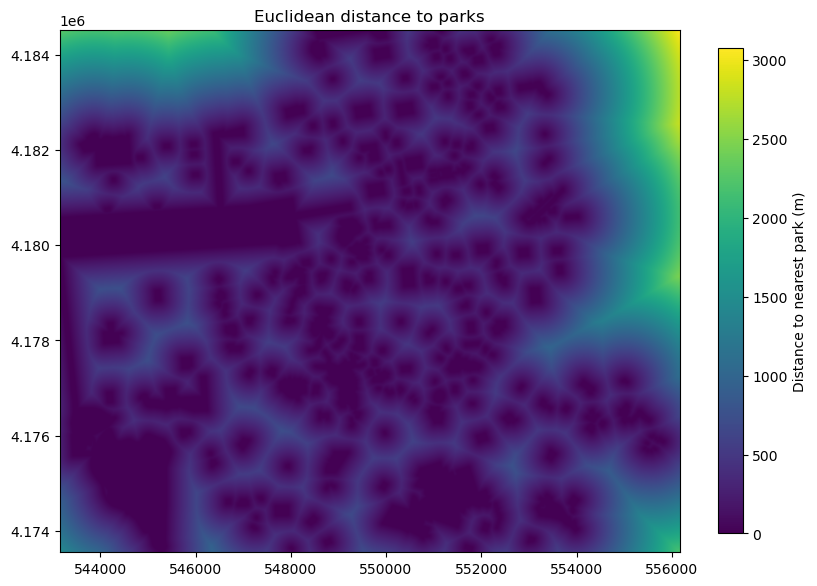

In [6]:
#Check the output
import numpy as np
import matplotlib.pyplot as plt
from osgeo import gdal

ds = gdal.Open(out_raster)
band = ds.GetRasterBand(1)
arr = band.ReadAsArray().astype(float)
nd = band.GetNoDataValue()
if nd is not None:
    arr[arr == nd] = np.nan

# Quick checks
print("Size:", ds.RasterXSize, "x", ds.RasterYSize)
print("Pixel size:", ds.GetGeoTransform()[1], "m")
print("CRS:", ds.GetSpatialRef().GetName())
print(f"Min {np.nanmin(arr):.1f}  Max {np.nanmax(arr):.1f}  Mean {np.nanmean(arr):.1f} m")
print(f"% pixels = 0 (inside a park): {(arr == 0).mean()*100:.1f}%")

# Map coordinates so other layers can be drawn on top
gt = ds.GetGeoTransform()
extent = [gt[0], gt[0] + gt[1]*ds.RasterXSize,
          gt[3] + gt[5]*ds.RasterYSize, gt[3]]

fig, ax = plt.subplots(figsize=(10, 9))
im = ax.imshow(arr, extent=extent, cmap="viridis")
fig.colorbar(im, ax=ax, label="Distance to nearest park (m)", shrink=0.7)
ax.set_title("Euclidean distance to parks")
plt.show()

ds = None
